In [34]:
import sys

import pandas as pd
import numpy as np
import mhealpy as mhp
from astropy.table import QTable
from astropy.io import fits

sys.path.insert(1, '/Users/cristozilleruelo/Rubicube-Ampel-HU-astro/Rubicube')
from ic_visualization_clean import read_map, plot_map, evaluate_map, get_map_area, \
    get_moc_map_metadata, get_max_ra_dec_from_map, is_source_in_contour_area

In [2]:
icecat1_path = '/Users/cristozilleruelo/Desktop/DESY/Thesis/IceCat-1/IceCube_Gold_Bronze_Tracks.csv'

In [13]:
icecat1 = pd.read_csv(icecat1_path)

print('Total alerts: ', len(icecat1))
print('Gold alerts: ', len(icecat1[icecat1['I3TYPE'] == 'gfu-gold']))
print('Gold alerts dec <= 30: ', len(icecat1[(icecat1['DEC']<=30) & (icecat1['I3TYPE'] == 'gfu-gold')]))
print('Gold alerts dec <= 0: ', len(icecat1[(icecat1['DEC']<=0) & (icecat1['I3TYPE'] == 'gfu-gold')]),
' -->  Rubin observable gold / total = ', len(icecat1[(icecat1['DEC']<=0) & (icecat1['I3TYPE'] == 'gfu-gold')]) / len(icecat1))

Total alerts:  348
Gold alerts:  92
Gold alerts dec <= 30:  78
Gold alerts dec <= 0:  19  -->  Rubin observable gold / total =  0.05459770114942529


In [7]:
icecat1.keys()

Index(['NAME', 'RUNID', 'EVENTID', 'START', 'EVENTMJD', 'I3TYPE', 'RA', 'DEC',
       'RA_ERR_PLUS', 'RA_ERR_MINUS', 'DEC_ERR_PLUS', 'DEC_ERR_MINUS',
       'ENERGY', 'FAR', 'SIGNAL', 'CASCADE_SCR', 'SKIMMING_SCR', 'START_SCR',
       'STOP_SCR', 'THRGOING_SCR', 'CR_VETO', 'OTHER_I3TYPES'],
      dtype='object')

In [36]:
map_path='/Users/cristozilleruelo/Desktop/DESY/Thesis/IceCat-1/fits/IceCube_IceCube_Gold_Bronze_Tracks_2023/Run137537_52990531_nside512.fits.gz'
# skymap, header = hp.read_map('./fits_files/Run132043_80110393_nside1024.fits.gz',h=True, verbose=False)
skymap, header = hp.read_map(map_path,h=True, verbose=False)
map_data = {
    'skymap': skymap,
    'header': header,
    'alert_name': 'Run137537_52990531_nside512'
}


/var/folders/9g/fpz1sy1x4jbc8fm9s02wgv9c0000gn/T/ipykernel_11480/1295730258.py:3: HealpyDeprecationWarning: "verbose" was deprecated in version 1.15.0 and will be removed in a future version. 
  skymap, header = hp.read_map(map_path,h=True, verbose=False)


(<matplotlib.image.AxesImage at 0x1259a1820>, <Mollview: >)

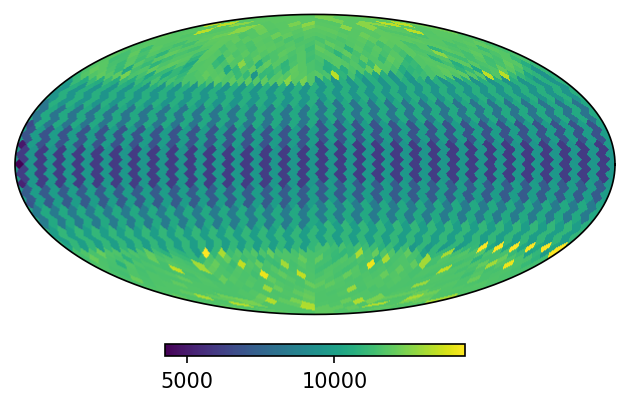

In [60]:
# skymap = QTable.read(map_path)
# _, header = fits.getdata(map_path, header=True)
map_moc = mhp.HealpixMap(skymap, nside=512)
map_moc.plot()

In [58]:
skymap[0][0]

array([11868.152, 11907.121, 12363.461, ..., 11868.152, 11868.152,
       11868.152], shape=(1024,), dtype='>f4')